# The Moving Average Filter
The moving average is the most common filter in DSP, mainly because it is the easiest digital filter to understand and use. In spite of its simplicity, the moving average filter is optimal for a common task: reducing random noise while retaining a sharp step response. This makes it the premier filter for time domain encoded signals. However, the moving average is the worst filter for frequency domain encoded signals, with little ability to separate one band of frequencies from another. Relatives of the moving average filter include the Gaussian, Blackman, and multiple-pass moving average. These have slightly better performance in the frequency domain, at the expense of increased computation time. 

## Implementation by Convolution
The moving average can be computed using the following two equations:

1. For an asymmetric implementation:
$$y[i]=\frac{1}{M} \sum\limits^{M-1}_{j=0}{x[i+j]}$$

2. For a symmetric implementation:
$$y[i]=\frac{1}{M} \sum\limits^{M/2-1}_{j=-M/2}{x[i+j]}$$

Now it is your turn to implement the moving average by convolution for both asymmetric and symmetric types. For this, you will create a function called `moving_average` that takes as input an array `x`, a value `M` for the number of points to use the moving average, and a `symmetry` key for selecting between symmetric (`sym`) and asymmetric (`asym`) implementations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

import re
import datetime
import time
import requests
import json

In [2]:
def moving_average(x, M = 5, symmetry = 'sym'):
    """ 
    Function that calculates the moving average of a signal in a symmetric and asymmetric form.
    Note: Be sure to run i from 0 to N. 
    Note: The limit of j depends on the type of symmetry.
  
    Parameters: 
    x (numpy array): Array of numbers representing the signal to be analyzed.
    M (integer): Number of point for the moving average filter.
    symmetry (string): String value for the type of symmetry being used, can be 'sym' or 'asym'.
  
    Returns: 
    numpy array: Returns filter response.
  
    """
    ### BEGIN SOLUTION
    N = len(x)
    y = np.zeros(N)
    m = int(M/2)

    
    #if(symmetry == 'asym'):
    #    for i in range(N-M):
    #        for j in range(M):
    #            y[i] = y[i] + x[i+j]
    #            
    #elif(symmetry == 'sym'):
    #    for i in range(m,N-m):
    #        for j in range(-m,m):
    #            y[i] = y[i] + x[i+j]
                
                
    if(symmetry == 'asym'):
        for i in range(N):
            for j in range(M):
                if (i+j)<N:
                    y[i] = y[i] + x[i+j]
                
    elif(symmetry == 'sym'):
        for i in range(N):
            for j in range(-m,m):
                if (i+j)<N:
                    y[i] = y[i] + x[i+j]
                
    return y/M
    ### END SOLUTION

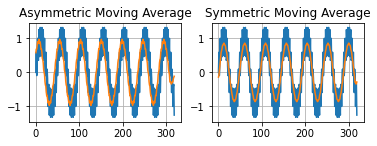

In [3]:
x = np.loadtxt(fname = "waveforms.dat").flatten()
y_asym = moving_average(x, M=11, symmetry = 'asym')
y_sym = moving_average(x, M=11, symmetry = 'sym')

with open('ma.pkl', 'rb') as file:
    y_asym_pkl, y_sym_pkl = pickle.load(file)

assert np.allclose(y_asym, y_asym_pkl, atol=0.01)
assert np.allclose(y_sym, y_sym_pkl, atol=0.01)

plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(x)
plt.plot(y_asym)
plt.title('Asymmetric Moving Average')
plt.grid('on')


plt.subplot(2,2,2)
plt.plot(x)
plt.plot(y_sym)
plt.title('Symmetric Moving Average')
plt.grid('on')

Now let's make a signal with additive gaussian noise to test how it works by removing noise from a signal:

In [4]:
# Create an array t with a range of values between 0 (inclusive) 
# and 35 (exclusive) use a step size of 0.01
### BEGIN SOLUTION
t = np.arange(0,35,0.01)
### END SOLUTION

# Create an array named signal with a sine function with amplitude of 1, and evaluate the t array
### BEGIN SOLUTION
signal = 1*np.sin(t)
### END SOLUTION

np.random.seed(42)
# Create a random signal with a normal distribution of size of t
# Assign a maximum amplitude of 0.10
# Name this array noise
# You can search for np.random.normal
### BEGIN SOLUTION
noise = 0.10*np.random.normal(size=len(t)) #Try to use np.random.uniform
### END SOLUTION

# Add both signal an noise and name it noise_signal.
### BEGIN SOLUTION
noise_signal = signal + noise
### END SOLUTION

# Apply your moving_average function to the noise_signal with 5 points.
### BEGIN SOLUTION
noiseless_signal = moving_average(noise_signal, M=5, symmetry = 'asym')
### END SOLUTION

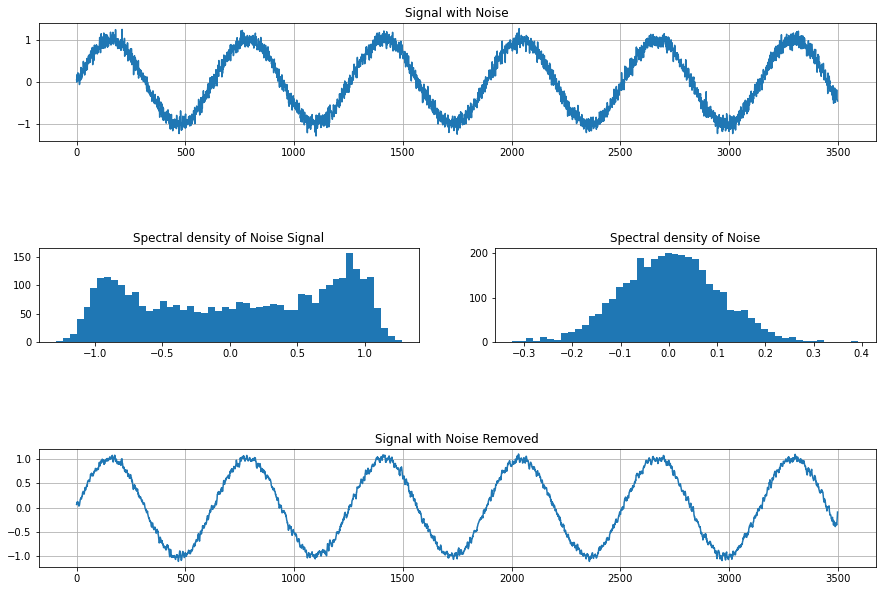

In [5]:
with open('noise_remove.pkl', 'rb') as file:
    t_pkl, signal_pkl, noise_pkl, noise_signal_pkl, noiseless_signal_pkl = pickle.load(file)
    
    
assert np.allclose(t, t_pkl)
assert np.allclose(signal, signal_pkl, atol=0.01)
assert np.allclose(noise, noise_pkl, atol=0.01)
assert np.allclose(noise_signal, noise_signal_pkl, atol=0.01)
assert np.allclose(noiseless_signal, noiseless_signal_pkl, atol=0.01)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(4, 1, 1)
plt.plot(noise_signal);
plt.title("Signal with Noise")
plt.grid(True)

plt.subplot(5, 2, 5)
plt.hist(noise_signal, 50);
plt.title("Spectral density of Noise Signal")

plt.subplot(5, 2, 6)
plt.hist(noise, 50)
plt.title("Spectral density of Noise")

plt.subplot(4, 1, 4)
plt.plot(noiseless_signal)
plt.title("Signal with Noise Removed")
plt.grid(True);

## Frequency Response

The frequency response of the moving average filter can be calculated by the Fourier transform of the rectangular pulse and is given by:

$$H[f]=\frac{\sin{(\pi f M)}}{M\sin{(\pi f)}} $$

The roll-off is very slow and the stopband attenuation is ghastly. Clearly, the moving average filter cannot separate one band of frequencies from another. Remember, good performance in the time domain results in poor performance in the frequency domain, and vice versa. In short, the moving average is an exceptionally good smoothing filter (the action in the time domain), but an exceptionally bad low-pass filter (the action in the frequency domain). 

In the following part you will need to implement a function called `frequency_response` that will take as input two arguments, one being an array of numbers representing the frequency of interest `f`, and the other an integer value `M` which represent the number of points for the moving average filter. With these parameters, the function will return $H[f]$ as described before.

In [6]:
def frequency_response(f, M):
    """ 
    Function that returns the frequency response of a moving average filter.
  
    Parameters: 
    f (numpy array): Array of numbers representing the input frequency to analyze.
    M (integer): Number of point for the moving average filter.
  
    Returns: 
    numpy array: Returns filter response.
  
    """
    ### BEGIN SOLUTION
    H = np.ones(len(f))
    H[1:] =  np.sin(np.pi*f[1:]*M)/(M*np.sin(np.pi*f[1:]))
    return H
    ### END SOLUTION

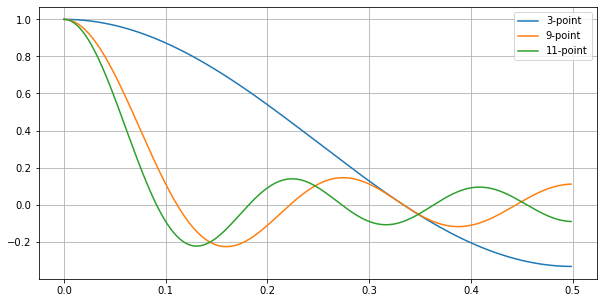

In [7]:
with open('freq_response.pkl', 'rb') as file:
    H1_pkl, H2_pkl, H3_pkl = pickle.load(file)


N = len(x)
f = np.arange(0, 0.5, 0.5/N)
m1 = 3
m2 = 9
m3 = 11

plt.rcParams["figure.figsize"] = (10,5)

H1 = frequency_response(f, m1)
H2 = frequency_response(f, m2)
H3 = frequency_response(f, m3)
plt.plot(f,H1, label='{}-point'.format(m1))
plt.plot(f,H2, label='{}-point'.format(m2))
plt.plot(f,H3, label='{}-point'.format(m3))
plt.grid(True)
plt.legend()


assert np.allclose(H1, H1_pkl, atol=0.001)
assert np.allclose(H2, H2_pkl, atol=0.001)
assert np.allclose(H3, H3_pkl, atol=0.001)

## Multiple-pass Moving Average Filter
Multiple-pass moving average filters involve passing the input signal through a moving average filter two or more times. Two passes are equivalent to using a triangular filter kernel (a rectangular filter kernel convolved with itself). After four or more passes, the equivalent filter kernel looks like a Gaussian (recall the [Central Limit Theorem](https://en.wikipedia.org/wiki/Central_limit_theorem) ).

The code below is an example of convolving a step pulse with itself multiple times. Notice the effect of multiple convolutions.

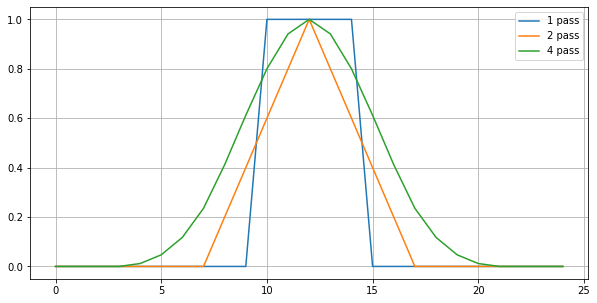

In [8]:
plt.rcParams["figure.figsize"] = (10,5)

step = np.append(np.zeros(10),np.ones(5))
step = np.append(step, np.zeros(10))

triangular = np.convolve(step,step)
gaussian = np.convolve(triangular,triangular)

plt.plot(step, label='1 pass')
plt.plot(triangular[12:-12]/np.max(triangular), label='2 pass')
plt.plot(gaussian[3*12:-3*12]/np.max(gaussian), label='4 pass')

plt.grid(True)
plt.legend();

Implement a multiple-pass moving average filter to the input signal `noise_signal` with a 5 point symmetric moving average.

In [9]:
# Filter noise_signal with a 5-point symmetric moving average fiter.
# Assign the result to one_pass variable
### BEGIN SOLUTION
one_pass = moving_average(noise_signal, M=5, symmetry = 'sym')
### END SOLUTION

# Filter one_pass with a 5-point symmetric moving average fiter.
# Assign the result to two_pass variable
### BEGIN SOLUTION
two_pass = moving_average(one_pass, M=5, symmetry = 'sym')
### END SOLUTION

# Filter two_pass with a 5-point symmetric moving average fiter.
# Assign the result to three_pass variable
### BEGIN SOLUTION
three_pass = moving_average(two_pass, M=5, symmetry = 'sym')
### END SOLUTION

# Filter three_pass with a 5-point symmetric moving average fiter.
# Assign the result to four_pass variable
### BEGIN SOLUTION
four_pass = moving_average(three_pass, M=5, symmetry = 'sym')
### END SOLUTION


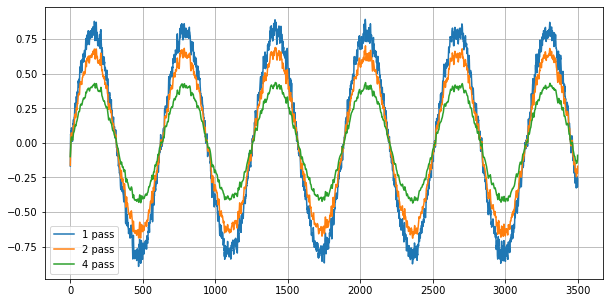

In [10]:
with open('filter_passes.pkl','rb') as file:
    one_pass_pkl, two_pass_pkl, three_pass_pkl, four_pass_pkl = pickle.load(file)
    
    
assert np.allclose(one_pass_pkl, one_pass, atol=0.01)
assert np.allclose(two_pass_pkl, two_pass, atol=0.01)
assert np.allclose(three_pass_pkl, three_pass, atol=0.01)
assert np.allclose(four_pass_pkl, four_pass, atol=0.01)

plt.plot(one_pass, label='1 pass')
plt.plot(two_pass, label='2 pass')
plt.plot(four_pass, label='4 pass')

plt.grid(True)
plt.legend()
plt.show()

## Recursive Moving Filter
A faster implementation of the moving average filter is done by using recursion. To show this method we can imagine passing an input signal, $x[ ]$, through a seven point moving average filter to form an output signal, $y[ ]$. Now look at how two adjacent output points, $y[25]$ and $y[26]$, are calculated:


$$y[25] = x[22] + x[23] +x[24] + x[25] + x[26] + x[27] + x[28]$$

$$y[26] = x[23] +x[24] + x[25] + x[26] + x[27] + x[28] + x[29]$$

By looking at $y[25]$ and $y[26]$ we can write:

$$ y[26] = y[25] + x[29] - x[22]$$

We can even generalize as follows:

$$y[i] = y[i-1] + x[i+p] - x[i-q]$$

$$\textrm{with} \quad p = \frac{(M-1)}{2}  \quad \textrm{and}  \quad q = p + 1$$


Implement a recursive moving average function called `recursive_moving_average` for an input signal `x` and a variable number of points `M`. Notice that this function can only be implemented in a symmetric form.

In [11]:
def recursive_moving_average(x, M = 5):
    """ 
    Function that calculates the recursive moving average of a signal in a symmetric form.
  
    Parameters: 
    x (numpy array): Array of numbers representing the signal to be analyzed.
    M (integer): Number of point for the moving average filter.
  
    Returns: 
    numpy array: Returns filter response.
  
    """
    ### BEGIN SOLUTION
    N = len(x)
    y = np.zeros(N)
    acc = 0

    for i in range(M):
        acc = acc + x[i]
    y[int(M/2)] = acc/M


    p = int((M-1)/2)
    q = p + 1

    for k in range(int(M/2)+1,N-int(M/2)):
            acc = acc + x[k+p] -x[k-q]
            y[k] = acc/M
        
    return y
    ### END SOLUTION

In [12]:
with open('denoise.pkl', 'rb') as file:
    denoise_pkl = pickle.load(file)
    
denoise = recursive_moving_average(noise_signal, M=5)

assert np.allclose(denoise_pkl, denoise, atol=0.01)

## Comparison between Moving Average and Recursive Moving Average
The following example shows a comparison between both models and the error between them. As it can be seen, the error is a systematically one, and a further study can be developed. 

In [13]:
x = np.loadtxt(fname = "waveforms.dat").flatten()

# Compare a moving average filter and a recursive moving average filter of 11 points.
# Assign to y1 the moving average implementation
# Assign to y2 the recursive moving average implementation
# Use as input the signal x
### BEGIN SOLUTION
M = 11
y1 = moving_average(x, M = M, symmetry = 'sym')
y2 = recursive_moving_average(x, M = M)
### END SOLUTION

# Find the absolute error between y1 and y2
### BEGIN SOLUTION
error = np.abs(y1-y2)
### END SOLUTION

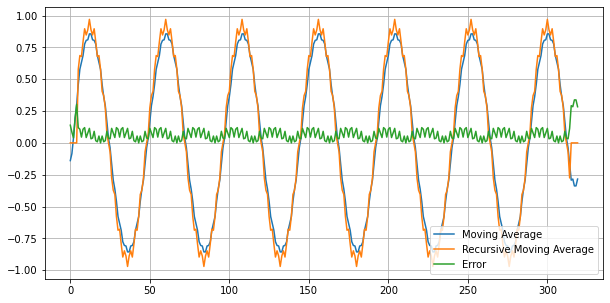

In [14]:
with open('compare.pkl', 'rb') as file:
    y1_pkl, y2_pkl, error_pkl = pickle.load(file)
    
    
assert np.allclose(y1_pkl, y1, atol=0.01)
assert np.allclose(y2_pkl, y2, atol=0.01)
assert np.allclose(error_pkl, error, atol=0.01)

plt.plot(y1, label = 'Moving Average')
plt.plot(y2, label = 'Recursive Moving Average')
plt.plot(error, label = 'Error')
plt.legend()
plt.grid(True)
plt.show()

# Crypto Market Example
In this example we will use the `moving_average` function developed at the beggining of this Jupyter Notebook to analize the Crypto market. Moving averages are extremely popular technical indicators to analyze trends. However, they are best used in conjunction with other indicators. 

Moving Average analysis can help to determine if the current market is a bullish or bearish, it can also serve to define selling o buying opportunities. You can read more about it [here](https://bitsgap.com/blog/best-indicators-for-the-crypto-market-moving-average).

In [15]:
def get_unix_time(data):
    """
    Auxiliary function to convert date in to unix time.
    
    Parameters: 
    data (string): Date format is 'YYYY-MM-DD HH:MM', for example '2020-02-25 17:20'
    
    Returns: 
    float: Returns a float number representing a UNIX timestamp .
    
    """
    date =  re.split(r'-| |:', data)    
    timestamp =  datetime.datetime(int(date[0]), int(date[1]), 
                                   int(date[2]), int(date[3]), int(date[4]))
    return time.mktime(timestamp.timetuple())

In [16]:
# Set initial date to 00:00 of january 1st, 2018 and return it as a unix time
# Use a variable named initial_time for this task.
### BEGIN SOLUTION
initial_time = get_unix_time('2018-01-01 00:00')
### END SOLUTION

# Set final date to 00:00 of july 11th, 2022 and return it as a unix time
# Use a variable named final_time for this task.
### BEGIN SOLUTION
final_time = get_unix_time('2022-07-11 00:00')
### END SOLUTION

# Assign to a variable named cryto a string 'bitcoin'
### BEGIN SOLUTION
crypto = 'bitcoin'
### END SOLUTION

# Assign to a variable named fiat a string 'usd'
### BEGIN SOLUTION
fiat = 'usd'
### END SOLUTION

In [17]:
url = f'https://api.coingecko.com/api/v3/coins/\
{crypto}/market_chart/range?vs_currency={fiat}&from={initial_time}&to={final_time}'

assert url=='https://api.coingecko.com/api/v3/coins/bitcoin/market_chart/range?vs_currency=usd&from=1514786400.0&to=1657519200.0'

In [18]:
response = requests.get(url)
result = np.array(response.json()['prices'])

# Create a variable named moving_average_50 and assign the symmetric 50 point moving average.
# Use the moving_average function developed before.
# Notice that we are interested in the current values for the moving average, so it will be 
# a good idea to calculate the moving average by flipping our data. (Just don't for get to
# return it to it's normal form when plotting)
### BEGIN SOLUTION
moving_average_50 = moving_average(np.flip(result[:,1]), M = 50, symmetry = 'asym')
### END SOLUTION

# Create a variable named moving_average_100 and assign the symmetric 100 point moving average.
# Use the moving_average function developed before.
# Notice that we are interested in the current values for the moving average, so it will be 
# a good idea to calculate the moving average by flipping our data. (Just don't for get to
# return it to it's normal form when plotting)
### BEGIN SOLUTION
moving_average_100 = moving_average(np.flip(result[:,1]), M = 100, symmetry = 'asym')
### END SOLUTION

# Create a variable named moving_average_200 and assign the symmetric 200 point moving average.
# Use the moving_average function developed before.
# Notice that we are interested in the current values for the moving average, so it will be 
# a good idea to calculate the moving average by flipping our data. (Just don't for get to
# return it to it's normal form when plotting)
### BEGIN SOLUTION
moving_average_200 = moving_average(np.flip(result[:,1]), M = 200, symmetry = 'asym')
### END SOLUTION

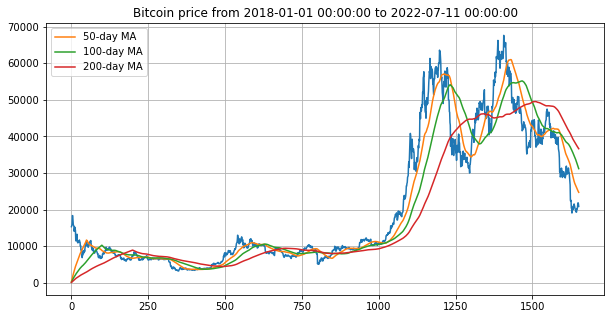

In [19]:
with open('moving_average_bitcoin.pkl', 'rb') as file:
    moving_average_50_pkl, moving_average_100_pkl, moving_average_200_pkl = pickle.load(file)
    
    
assert np.allclose(moving_average_50_pkl, moving_average_50, atol=0.10)
assert np.allclose(moving_average_100_pkl, moving_average_100, atol=0.10)
assert np.allclose(moving_average_200_pkl, moving_average_200, atol=0.10)


plt.plot(result[:,1])
plt.plot(np.flip(moving_average_50), label='50-day MA')
plt.plot(np.flip(moving_average_100), label='100-day MA')
plt.plot(np.flip(moving_average_200), label='200-day MA')
plt.title(f'{crypto.capitalize()} price from {datetime.datetime.fromtimestamp(initial_time)} \
to {datetime.datetime.fromtimestamp(final_time)}')
plt.legend()
plt.grid(True)
plt.show()

#### Reference
* http://www.dspguide.com/ch15.htm
* https://www.bitcoinmarketjournal.com/moving-averages-bitcoin/